# Segmentierungskarten der latenten TTA

*Wo* verbessert oder zerstört der Gradient-Ascent die Segmentierung? Die Pickles enthalten nur
Dice-Zahlen, keine Masken — dieses Notebook holt die Masken zurück.

**Kein Neutraining nötig.** Die U-Net- und Score-Predictor-Checkpoints liegen alle in
`pre-trained/`; dieses Notebook lädt sie, hängt dieselben latenten Adapter an und fährt den Ascent
für ausgewählte Batches erneut, wobei es die binären Masken bei den interessanten Schritten
mitschneidet. `adapt_with_snapshots` unten spiegelt `run_latent_tta` aus
`src/model/latent_adapter.py` (Objective = mittleres μ̂, Adam, Reset pro Batch) — wird dort etwas
geändert, muss es hier nachgezogen werden.

**Zwei Dinge, die das reproduzierbar machen:**

* `granularity: batch` — die Adapter werden pro Batch gefittet und von allen 32 Bildern geteilt.
  Ein Case lässt sich deshalb nur zusammen mit *seinem Original-Batch* nachstellen, nicht allein.
  Der Test-Loader läuft mit `shuffle=False`, also ist Batch `i // 32`, Position `i % 32`.
* Der Ascent ist GPU-nichtdeterministisch. Die Zelle „Sanity-Check" vergleicht deshalb den
  nachgerechneten Dice bei Schritt 0 mit `dice_before` aus dem Pickle — das muss exakt passen,
  danach darf ein einzelner Case leicht abweichen.

In [1]:
import os, sys, glob, pickle, hashlib
from pathlib import Path

import numpy as np
import torch
import matplotlib.pyplot as plt
from omegaconf import OmegaConf

# repo root -- ueber Marker gesucht, damit die Zelle auch nach dem chdir unten erneut laeuft
REPO = next(str(p) for p in [Path.cwd(), *Path.cwd().parents] if (p / "src" / "apps").is_dir())
os.chdir(f"{REPO}/src/apps")          # Configs und Checkpoint-Pfade sind relativ zu src/apps
sys.path.insert(0, "..")

from dataset import PMRIDataset
from model.unet import get_unet_module
from utils import find_unet_checkpoint
from model.score_adapter import get_score_prediction_module
from model.latent_adapter import (resolve_swivels, attach_latent_adapters,
                                  reset_adapters, latent_parameters)

CFG_DIR = f"{REPO}/src/configs"
RESULTS = f"{REPO}/results"
CACHE = f"{RESULTS}/_segmentation_maps_cache.pkl"
DEVICE = "cuda:4" if torch.cuda.is_available() else "cpu"
BATCH_SIZE = 32                        # cfg.data.batch_size, bestimmt die Batch-Zuordnung
PREDICTOR = 0                          # cleanHalf_0

DOMAINS = {"promise12": "PROMISE12",
           "threet-to-onepointfivet": "3T→1.5T",
           "onepointfivet-to-threet": "1.5T→3T"}
# Die drei Budgets aus den Ergebnisordnern; 0 ist die un-adaptierte Referenz.
SNAP_STEPS = [0, 20, 100, 1000]
T_REF = 100                            # Schritt, auf den sich die Case-Auswahl bezieht
# bester globaler Stopp pro Domain -- nur noch Annotation, keine eigene Spalte mehr
T_STAR = {"promise12": 100, "threet-to-onepointfivet": 61, "onepointfivet-to-threet": 1000}
PRED_TAG = "dice_predictor-adversarial-location-concentration_beta-cleanHalf_"

print("device:", DEVICE)

device: cuda:4


## 1 · Modelle laden

U-Net und Score-Predictor kommen aus denselben Checkpoints, die auch `eval_latent_tta.py`
benutzt. Die latenten Adapter sitzen an `adapt_sites: [0, 17]` aus `configs/tta/latent_affine.yaml`.

In [2]:
def build_cfg(split):
    cfg = OmegaConf.create({
        "data":    OmegaConf.load(f"{CFG_DIR}/data/pmri.yaml"),
        "unet":    OmegaConf.load(f"{CFG_DIR}/unet/monai_unet.yaml"),
        "model":   OmegaConf.load(f"{CFG_DIR}/model/score_predictor.yaml"),
        "trainer": OmegaConf.load(f"{CFG_DIR}/trainer/score_predictor_trainer.yaml"),
        "tta":     OmegaConf.load(f"{CFG_DIR}/tta/latent_affine.yaml"),
    })
    cfg.data.split = split
    cfg.unet.out_channels = 1
    cfg.model.num_classes = 2
    cfg.model.swivels = "first-embedding-last"
    return cfg


_STACK = {}


def get_stack(split, predictor=PREDICTOR):
    """(cfg, test-dataset, wrapper, adapters, checkpoint-name), gecacht pro Split.

    Das Test-Dataset wird direkt gebaut statt über das DataModule: dessen `setup("test")`
    lädt zusätzlich den Trainings-Split (mehrere Minuten, zweistellige GB), den hier
    niemand braucht. `PMRIDataset.from_split(..., "test", include_meta=True)` ist genau
    der Aufruf, den das DataModule intern für `dataset_test` macht — gleiche Reihenfolge,
    gleiches `non_empty_target=True`.
    """
    key = (split, predictor)
    if key in _STACK:
        return _STACK[key]

    cfg = build_cfg(split)
    ds_test = PMRIDataset.from_split(cfg.data.data_dir, split, "test", include_meta=True)

    unet_ckpt = find_unet_checkpoint(os.path.join(cfg.trainer.root_dir, cfg.unet.checkpoint_dir),
                                     dataset=cfg.data.dataset, split=split,
                                     dropout=cfg.unet.dropout, newest=True)
    cfg.unet.checkpoint_path = str(unet_ckpt)
    unet = get_unet_module(cfg=cfg.unet, metadata=OmegaConf.to_container(cfg.unet),
                           load_from_checkpoint=True).model

    sp_ckpt = sorted(glob.glob(
        f"{REPO}/pre-trained/score-predictors/score-predictors-using-logits/"
        f"pmri_{split}_*cleanHalf_{predictor}_*.ckpt"))[0]
    model = get_score_prediction_module(data_cfg=cfg.data, model_cfg=cfg.model, unet=unet,
                                        metadata=OmegaConf.to_container(cfg.model),
                                        ckpt=str(sp_ckpt)).to(DEVICE)
    model.eval()
    for p in model.parameters():
        p.requires_grad = False        # nur Aktivierungs-Gradienten, keine Gewichts-Gradienten

    wrapper = model.wrapper
    assert not wrapper.training, "wrapper muss im eval-Modus sein, sonst wandert μ̂ mit dem Batch"
    sites = resolve_swivels(model=wrapper.model, indices=cfg.tta.adapt_sites)
    adapters, _ = attach_latent_adapters(wrapper, sites, max_batch=BATCH_SIZE,
                                         input_shape=OmegaConf.to_object(cfg.data.input_shape),
                                         device=DEVICE)
    _STACK[key] = (cfg, ds_test, wrapper, adapters, os.path.basename(sp_ckpt))
    return _STACK[key]

## 2 · Ascent mit Masken-Snapshots

Identisch zu `run_latent_tta`, nur dass bei den gewünschten Schritten zusätzlich die binäre Maske,
der echte Dice und μ̂ pro Bild festgehalten werden.

In [3]:
def dice_binary(logits, target):
    pred = (logits > 0).float()
    t = target.float()
    inter = (pred * t).flatten(1).sum(1)
    denom = pred.flatten(1).sum(1) + t.flatten(1).sum(1)
    return torch.where(denom > 0, 2 * inter / denom, torch.ones_like(denom))


@torch.no_grad()
def _snapshot(wrapper, x, t):
    logits = wrapper(x)
    prediction = wrapper.prediction
    return {"mask": (logits > 0).squeeze(1).cpu().numpy().astype(np.uint8),
            "dice": dice_binary(logits, t).cpu().numpy(),
            "mu": prediction[:, 0, 0].cpu().numpy()}


def adapt_with_snapshots(split, batch_index, snap_at, predictor=PREDICTOR, lr=None):
    """Fährt den Ascent auf genau einem Original-Batch und schneidet Masken mit."""
    cfg, ds, wrapper, adapters, sp_name = get_stack(split, predictor)
    lr = cfg.tta.lr if lr is None else lr
    idx = list(range(batch_index * BATCH_SIZE, min((batch_index + 1) * BATCH_SIZE, len(ds))))
    items = [ds[i] for i in idx]
    x = torch.stack([it["input"] for it in items]).to(DEVICE).float()
    t = torch.stack([it["target"] for it in items]).to(DEVICE).long()
    t[t == -1] = 0

    reset_adapters(adapters)
    params = latent_parameters(adapters)
    for p in params:
        p.requires_grad_(True)
    opt = torch.optim.Adam(params, lr=lr)

    want = sorted(set(snap_at))
    snaps = {}
    for step in range(max(want) + 1):
        if step in want:
            snaps[step] = _snapshot(wrapper, x, t)
        if step == max(want):
            break
        with torch.enable_grad():
            wrapper(x)
            mu = wrapper.prediction[:, 0, 0].clamp(1e-6, 1 - 1e-6)
        opt.zero_grad(set_to_none=True)
        (-mu.mean()).backward()        # Adam minimiert, also negieren, um μ̂ zu maximieren
        opt.step()

    return {"snaps": snaps, "image": x[:, 0].cpu().numpy(), "target": t.squeeze(1).cpu().numpy(),
            "global_index": idx, "checkpoint": sp_name, "split": split, "batch": batch_index}

## 3 · Interessante Cases auswählen

Nicht von Hand gepickt, sondern über Regeln aus den vorhandenen Pickles. Δ wird bei
**Schritt 100** gemessen (`T_REF`), also an einer der gezeigten Spalten — nicht am
domänenspezifischen `t*`, sonst läge der Extrempunkt eines Cases zwischen zwei Bildern.

| Regel | Befund |
|---|---|
| größter Gewinn | Adaptation rettet kaputte Cases |
| Rettung `<0.2 → >0.7` | dasselbe, aber ohne Ausreißer-Argument |
| **typische Verbesserung** | wie der Normalfall aussieht, nicht der Rekord |
| größter Verlust @100 | der Preis derselben Regel |
| Kollaps: Spitze → 1000 | die Übersegmentierung, die den Zusammenbruch treibt |
| hohes μ̂, trotzdem Schaden | genau der Case, den das Gate aus Abschnitt 6 *nicht* schützt |

„Typisch" ist dabei definiert, nicht geraten: unter allen Cases mit Δ > 0.01 der
Median-Repräsentant in **beiden** Dimensionen — Δ *und* Ausgangs-Dice, jeweils auf ihre
Streuung normiert. Ein Case mit medianem Δ, der aber von 0.05 startet, wäre kein typischer
Verbesserungsfall; die zweite Achse verhindert das.

In [ ]:
def load_pickle(split, budget, predictor=PREDICTOR):
    path = sorted(glob.glob(
        f"{RESULTS}/latent_tta_{budget}_steps/pmri_{split}_{PRED_TAG}{predictor}_*/latent_tta.pkl"))[0]
    with open(path, "rb") as fh:
        return pickle.load(fh)["evaluation"][f"{split}_test"]


def select_cases(split, predictor=PREDICTOR, reference=T_REF):
    """Regelbasierte Auswahl; `reference` ist der Schritt, an dem Δ gemessen wird."""
    ev = load_pickle(split, 1000, predictor)
    C = ev["dice_per_step"].float().numpy()
    mu = ev["mu_before"].float().numpy()
    before, at_ref, at_end = C[:, 0], C[:, reference], C[:, -1]
    delta = at_ref - before
    gate_threshold = np.quantile(mu, 0.30)

    picks = []

    def add(tag, i):
        i = int(i)
        if any(p["case"] == i for p in picks):
            return
        picks.append({"tag": tag, "case": i, "batch": i // BATCH_SIZE, "pos": i % BATCH_SIZE,
                      "dice_0": before[i], f"dice_{reference}": at_ref[i], "dice_1000": at_end[i],
                      "mu_0": mu[i], "im Gate": bool(mu[i] < gate_threshold)})

    add("größter Gewinn @100", np.argmax(delta))
    rescue = np.where((before < 0.2) & (at_ref > 0.7))[0]
    if len(rescue):
        add("Rettung <0.2 → >0.7", rescue[np.argmax(delta[rescue])])

    # typische Verbesserung: unter den verbesserten Cases derjenige, der (Δ, dice_before)
    # am nächsten am Median dieser Gruppe liegt -- also weder Ausreißer im Gewinn noch im
    # Startniveau. Beide Achsen werden auf ihre Streuung normiert, sonst dominiert die mit
    # der größeren Spannweite die Auswahl.
    improved = np.where(delta > 0.01)[0]
    if len(improved):
        z = (((delta[improved] - np.median(delta[improved])) / (delta[improved].std() + 1e-9)) ** 2
             + ((before[improved] - np.median(before[improved])) / (before[improved].std() + 1e-9)) ** 2)
        add("typische Verbesserung @100", improved[np.argmin(z)])

    add("größter Verlust @100", np.argmin(delta))
    alive = np.where(before > 0.5)[0]
    add("Kollaps: Spitze → 1000", alive[np.argmax(C[alive].max(1) - at_end[alive])])
    outside = np.where(mu >= gate_threshold)[0]
    add("hohes μ̂, trotzdem Schaden", outside[np.argmin(delta[outside])])
    return picks


selection = {s: select_cases(s) for s in DOMAINS}
import pandas as pd

for split, picks in selection.items():
    ev = load_pickle(split, 1000)
    C = ev["dice_per_step"].float().numpy()
    d = C[:, T_REF] - C[:, 0]
    imp = d[d > 0.01]
    print(f"{DOMAINS[split]:<10} verbessert bei Schritt {T_REF}: {len(imp)}/{len(d)} Cases, "
          f"Median Δ {np.median(imp):+.3f}")

pd.concat({DOMAINS[s]: pd.DataFrame(v).set_index("tag") for s, v in selection.items()},
          names=["domain"]).round(3)

PROMISE12  verbessert bei Schritt 100: 735/1248 Cases, Median Δ +0.058
3T→1.5T    verbessert bei Schritt 100: 265/481 Cases, Median Δ +0.075
1.5T→3T    verbessert bei Schritt 100: 335/1121 Cases, Median Δ +0.031


case  batch  pos  dice_0  dice_100  \
domain    tag                                                              
PROMISE12 größter Gewinn @100          401     12   17   0.001     0.786   
          typische Verbesserung       1082     33   26   0.690     0.744   
          größter Verlust @100         324     10    4   0.759     0.575   
          hohes μ̂, trotzdem Schaden   121      3   25   0.808     0.655   
3T→1.5T   größter Gewinn @100          199      6    7   0.000     0.928   
          typische Verbesserung        117      3   21   0.783     0.857   
          größter Verlust @100         432     13   16   0.620     0.324   
          Kollaps: Spitze → 1000        10      0   10   0.867     0.776   
1.5T→3T   größter Gewinn @100          447     13   31   0.248     0.932   
          typische Verbesserung        127      3   31   0.586     0.618   
          größter Verlust @100         385     12    1   0.268     0.000   
          Kollaps: Spitze → 1000      1071     33   15   0.586     0.512   
          hohes μ̂, trotzdem Schaden   802     25    2   0.195     0.081   

                                      dice_1000   mu_0  im Gate  
domain    tag                                                    
PROMISE12 größter Gewinn @100             0.797  0.084     True  
          typische Verbesserung           0.742  0.710    False  
          größter Verlust @100            0.544  0.351     True  
          hohes μ̂, trotzdem Schaden      0.623  0.704    False  
3T→1.5T   größter Gewinn @100             0.888  0.030     True  
          typische Verbesserung           0.803  0.778    False  
          größter Verlust @100            0.205  0.684    False  
          Kollaps: Spitze → 1000          0.196  0.747    False  
1.5T→3T   größter Gewinn @100             0.935  0.308     True  
          typische Verbesserung           0.614  0.681    False  
          größter Verlust @100            0.000  0.420     True  
          Kollaps: Spitze → 1000          0.477  0.599     True  
          hohes μ̂, trotzdem Schaden      0.075  0.684    False

## 4 · Batches nachrechnen

Ein Batch je gebrauchtem `batch`-Index, gecacht in `results/_segmentation_maps_cache.pkl` — der
1000-Schritt-Ascent kostet ~2.7 min pro Batch, ein zweiter Notebook-Durchlauf ist danach sofort
fertig.

Der Cache wird gegen `snapshot_steps` geprüft: ein Eintrag, der die angeforderten Schritte nicht
alle enthält, wird neu gerechnet statt stillschweigend wiederverwendet. Ändert man also
`SNAP_STEPS`, laufen genau die betroffenen Batches nochmal — nicht alle, und nicht die falschen.

In [5]:
def snapshot_steps(split):
    """Für alle Domains dieselben Spalten -- die drei Budgets plus die Referenz bei 0."""
    return sorted(set(SNAP_STEPS))


def run_all(selection, cache_path=CACHE):
    """Rechnet fehlende Batches, split-weise, und gibt jeden Split danach wieder frei.

    Ein PMRI-Split belegt beim Laden mehrere GB; alle drei gleichzeitig im Speicher zu
    halten ist unnötig, weil jeder Batch nur seinen eigenen Split braucht.
    """
    import gc

    cache = {}
    if os.path.exists(cache_path):
        with open(cache_path, "rb") as fh:
            cache = pickle.load(fh)

    def usable(key, split):
        """Ein Cache-Eintrag zählt nur, wenn er alle angeforderten Schritte enthält --
        sonst hat eine frühere Zelle mit anderen SNAP_STEPS gerechnet."""
        entry = cache.get(key)
        return entry is not None and set(snapshot_steps(split)) <= set(entry["snaps"])

    todo = {(s, p["batch"]) for s, picks in selection.items() for p in picks}
    missing = sorted(k for k in todo if not usable(k, k[0]))
    print(f"{len(todo)} Batches gebraucht, {len(missing)} müssen gerechnet werden")

    done = 0
    for split in DOMAINS:
        batches = sorted(b for s, b in missing if s == split)
        if not batches:
            continue
        for batch in batches:
            done += 1
            print(f"  [{done}/{len(missing)}] {split} batch {batch} "
                  f"({max(snapshot_steps(split))} Schritte) ...", flush=True)
            cache[(split, batch)] = adapt_with_snapshots(split, batch, snapshot_steps(split))
            with open(cache_path, "wb") as fh:
                pickle.dump(cache, fh)
        _STACK.pop((split, PREDICTOR), None)      # Datamodule + Modelle wieder freigeben
        gc.collect()
        if torch.cuda.is_available():
            torch.cuda.empty_cache()
    return cache


runs = run_all(selection)
print("fertig:", len(runs), "Batches im Cache")

13 Batches gebraucht, 0 müssen gerechnet werden
fertig: 13 Batches im Cache


### Sanity-Check gegen die Pickles

Schritt 0 muss exakt reproduzieren — sonst stimmt die Batch- oder Case-Zuordnung nicht. Für die
späteren Schritte ist eine kleine Abweichung erwartet (nichtdeterministische GPU-Kernel, siehe
Abschnitt 4 im Per-Case-Notebook).

In [6]:
rows = []
for split in DOMAINS:
    ev = load_pickle(split, 1000)
    C = ev["dice_per_step"].float().numpy()
    for (s, batch), run in runs.items():
        if s != split:
            continue
        idx = run["global_index"]
        for step, snap in sorted(run["snaps"].items()):
            rows.append({"domain": DOMAINS[split], "batch": batch, "step": step,
                         "Dice Pickle": C[idx, step].mean(),
                         "Dice neu": snap["dice"].mean(),
                         "|Δ|": abs(C[idx, step].mean() - snap["dice"].mean())})
check = pd.DataFrame(rows)
worst_step0 = check[check.step == 0]["|Δ|"].max()
print(f"maximale Abweichung bei Schritt 0: {worst_step0:.2e}")
assert worst_step0 < 1e-4, "Schritt 0 reproduziert nicht — Batch-/Case-Zuordnung prüfen"
check.groupby(["domain", "step"])["|Δ|"].max().unstack().round(4)

maximale Abweichung bei Schritt 0: 0.00e+00


step,0,20,100,1000
domain,,,,
1.5T→3T,0.0,0.0046,0.0018,0.0019
3T→1.5T,0.0,0.0012,0.0073,0.0191
PROMISE12,0.0,0.0019,0.0057,0.0074


## 5 · Karten

* **blau** — richtig als Prostata erkannt (TP)
* **rot** — dazuerfunden (FP, Übersegmentierung)
* **orange** — übersehen (FN, Untersegmentierung)
* **grüne Kontur** — Ground Truth

Der Ausschnitt ist auf die Vereinigung aus Ground Truth und allen gezeigten Vorhersagen
zugeschnitten, sonst verschwindet die Prostata in 384×384 Hintergrund.

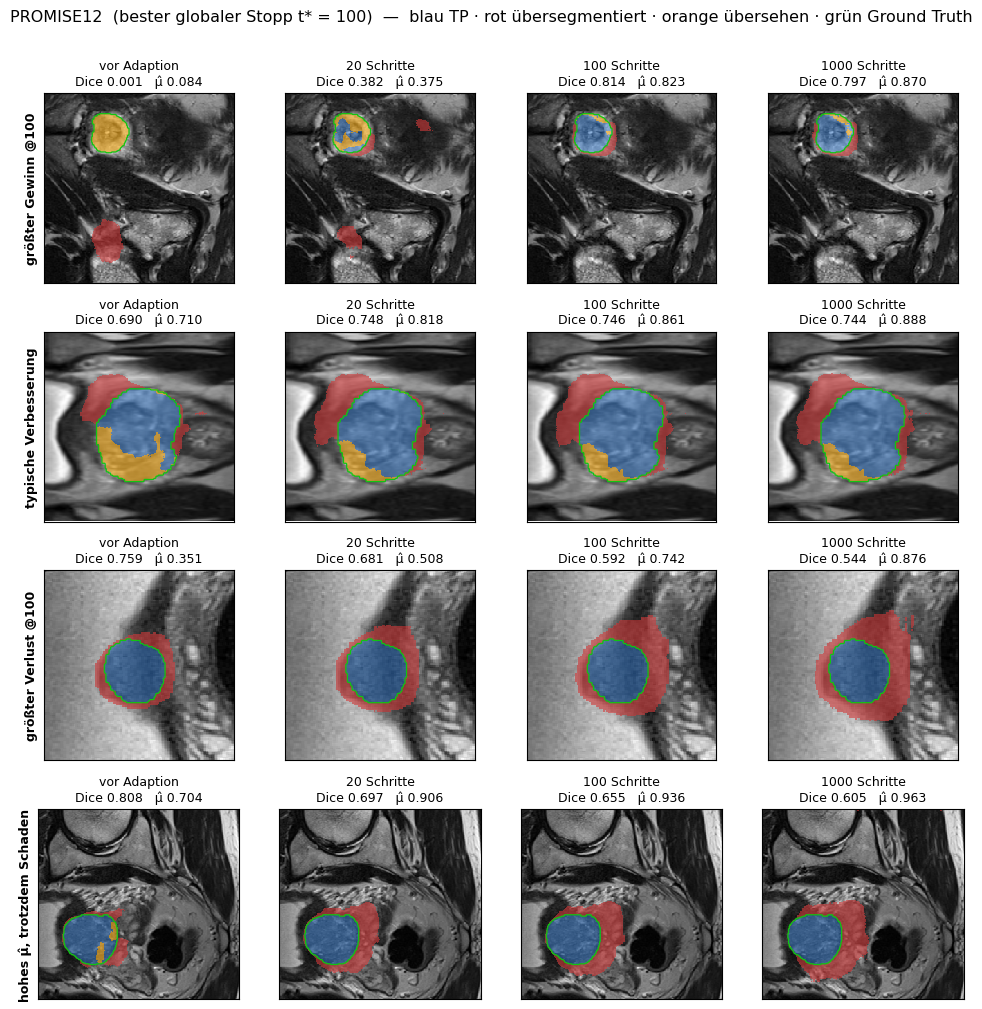

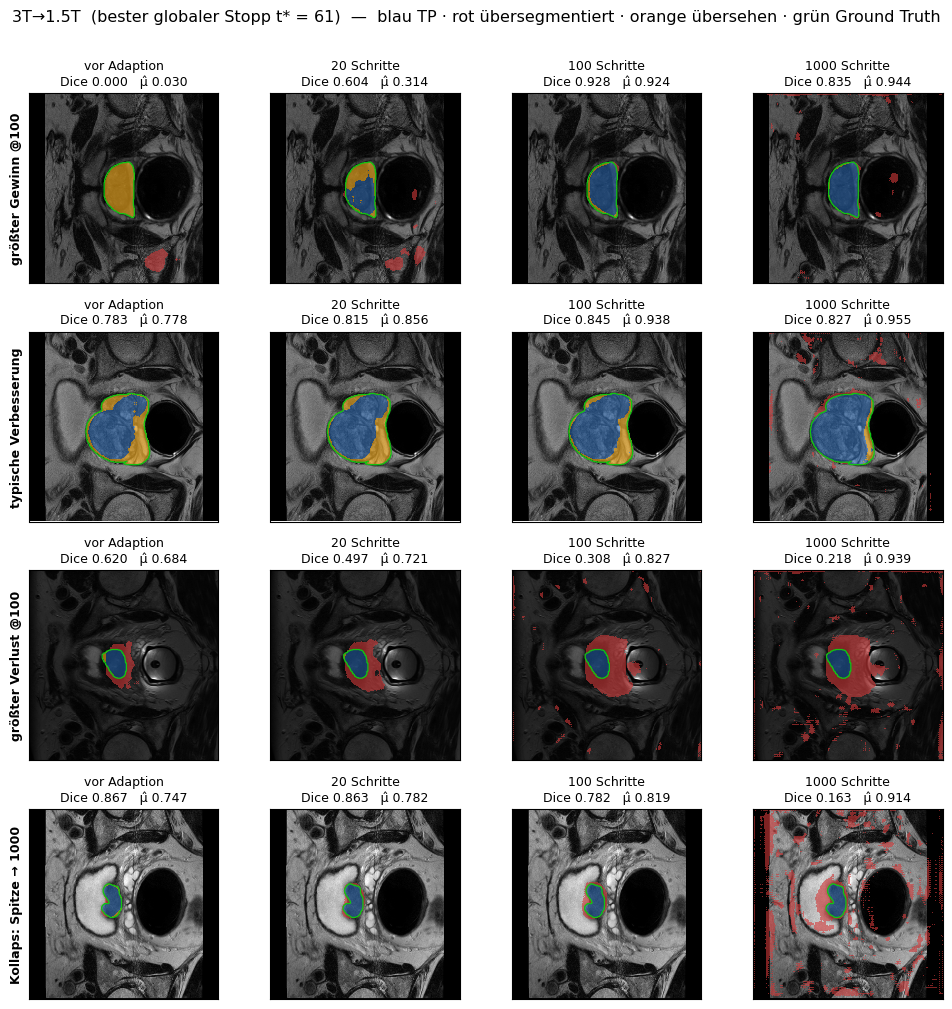

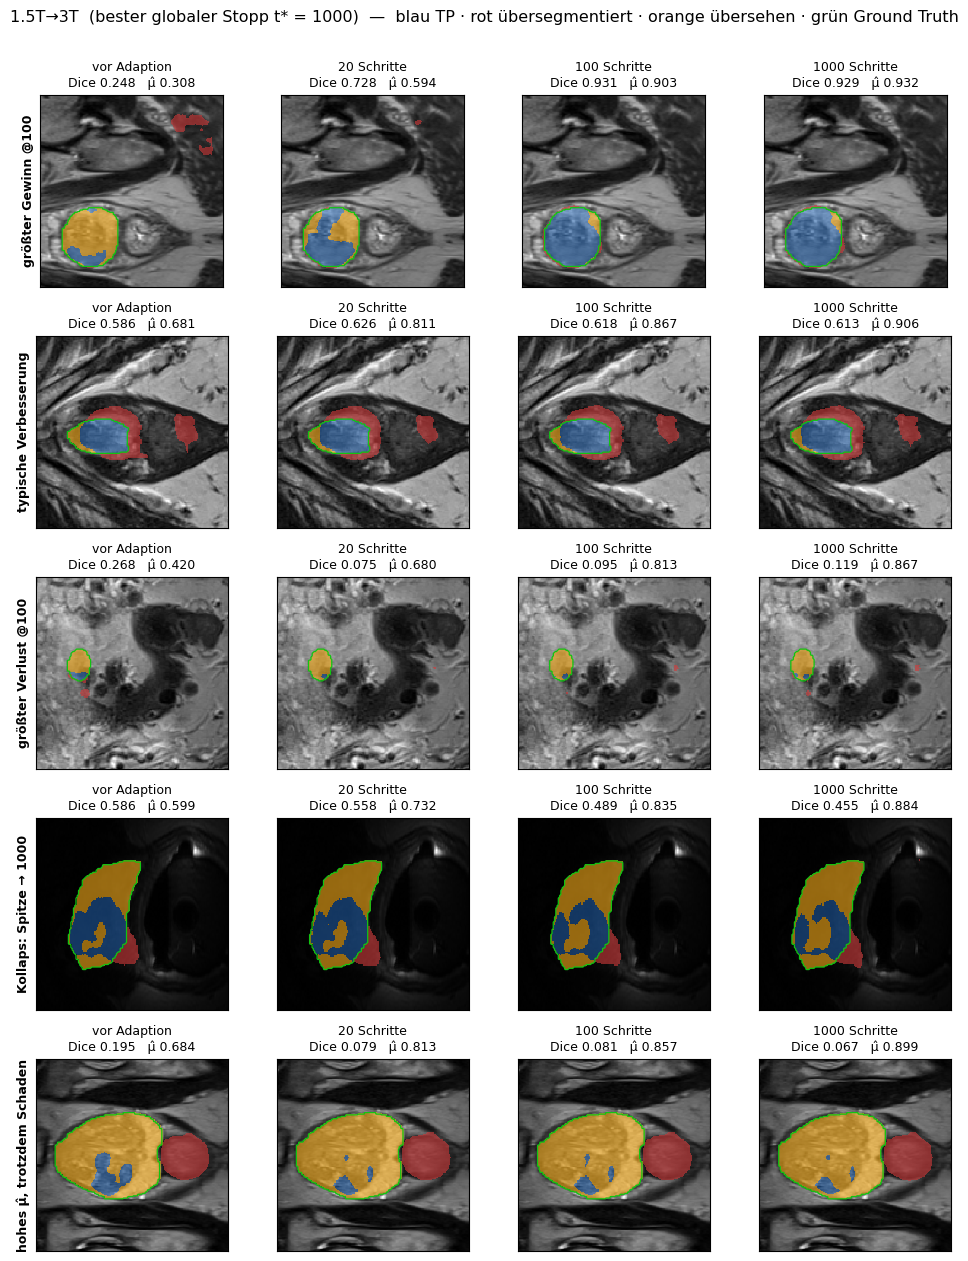

In [7]:
COL_TP = (0.16, 0.47, 0.84, 0.45)
COL_FP = (0.82, 0.23, 0.23, 0.60)
COL_FN = (0.98, 0.68, 0.10, 0.60)


def crop_box(masks, margin=26, shape=(384, 384)):
    union = np.any(np.stack(masks) > 0, axis=0)
    if not union.any():
        return slice(None), slice(None)
    ys, xs = np.where(union)
    half = max(ys.max() - ys.min(), xs.max() - xs.min()) / 2 + margin
    cy, cx = (ys.min() + ys.max()) / 2, (xs.min() + xs.max()) / 2
    y0, y1 = int(max(cy - half, 0)), int(min(cy + half, shape[0]))
    x0, x1 = int(max(cx - half, 0)), int(min(cx + half, shape[1]))
    return slice(y0, y1), slice(x0, x1)


def draw(ax, image, gt, pred, box):
    ax.imshow(image[box], cmap="gray", interpolation="nearest")
    overlay = np.zeros(image.shape + (4,))
    overlay[(pred == 1) & (gt == 1)] = COL_TP
    overlay[(pred == 1) & (gt == 0)] = COL_FP
    overlay[(pred == 0) & (gt == 1)] = COL_FN
    ax.imshow(overlay[box], interpolation="nearest")
    if gt.any():
        ax.contour(gt[box], [0.5], colors="#12c412", linewidths=0.9)
    ax.set_xticks([]); ax.set_yticks([])


def plot_domain(split, picks, runs, figsize_scale=2.5):
    steps = snapshot_steps(split)
    fig, axes = plt.subplots(len(picks), len(steps),
                             figsize=(figsize_scale * len(steps), figsize_scale * len(picks)),
                             squeeze=False)
    for r, pick in enumerate(picks):
        run = runs[(split, pick["batch"])]
        j = pick["pos"]
        gt = run["target"][j]
        image = run["image"][j]
        masks = [run["snaps"][s]["mask"][j] for s in steps] + [gt]
        box = crop_box(masks)
        for c, step in enumerate(steps):
            snap = run["snaps"][step]
            draw(axes[r, c], image, gt, snap["mask"][j], box)
            header = "vor Adaption" if step == 0 else f"{step} Schritte"
            axes[r, c].set_title(f"{header}\nDice {snap['dice'][j]:.3f}   "
                                 f"μ̂ {snap['mu'][j]:.3f}", fontsize=9)
        gate = "im Gate (30 %)" if pick["im Gate"] else "NICHT im Gate"
        axes[r, 0].set_ylabel(f"{pick['tag']}", #\ncase {pick['case']} · {gate}
                              fontsize=9, fontweight="bold")
    fig.suptitle(f"{DOMAINS[split]}  (bester globaler Stopp t* = {T_STAR[split]})  —  "
                 f"blau TP · rot übersegmentiert · orange übersehen · grün Ground Truth",
                 fontsize=11.5, y=1.005)
    fig.tight_layout()
    return fig


for split in DOMAINS:
    plot_domain(split, selection[split], runs)
    plt.show()

## 6 · Was in den Karten zu sehen ist

* **Die Gewinne sind Rekrutierung, keine Verfeinerung.** Bei den geretteten Cases ist die
  Baseline-Maske fast leer (Dice ≈ 0, alles orange). Der Ascent lässt die Vorhersage überhaupt
  erst entstehen — er korrigiert keine Kontur, er schaltet die Region an.
* **Die Verluste sind Übersegmentierung.** Auf den Schadensfällen wächst zwischen `t*` und 1000
  rot aus der Prostata heraus in Blase und Rektum. Genau das misst `fg_frac`, das auf 3T→1.5T um
  Faktor 2.4 steigt.
* **Derselbe Mechanismus, verschiedene Vorzeichen.** Wachsende Vorhersage hilft, solange die Maske
  zu klein war, und schadet, sobald sie passt. Deshalb hängt Δ so stark vom Baseline-Dice ab
  (Abschnitt 2 im Per-Case-Notebook) und deshalb wirkt ein Gate auf μ̂.
* **Die `NICHT im Gate`-Zeile ist der Restrisiko-Fall**: hohes μ̂, wird trotzdem beschädigt. Das
  30-%-Gate fängt diese Cases nicht — es reduziert ihre Zahl, macht sie aber nicht null.